# MMLongBench-Doc Retrieval Benchmark

Evaluates Colette retrieval methods against the **MMLongBench-Doc** benchmark (NeurIPS 2024),
using the VLM2Vec retrieval format (`VLM2Vec/MMLongBench-doc` on HuggingFace).

**Benchmark**: 135 multi-page PDF documents, 1091 expert-annotated questions, evidence_pages ground truth.  
**Metric**: NDCG@5 (standard for this benchmark), Hit@5, MRR.  
**Comparison**: our GME-Qwen2-VL-2B embedding vs published ColPali / BM25+OCR numbers.

## Phase 1: Embedding retrieval (image-to-image)
Embed all 6492 corpus pages with our embedding model.  
For each query, rank pages within its document by cosine similarity.  

## Phase 2: Full pipeline (requires PDFs)
Index PDFs with the full colette stack (embedding + hindex + BM25).  
Evaluate all 7 retrieval methods.


## 1. Setup & Configuration

In [1]:
import os, sys, json, math, time, warnings
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

colette_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(colette_root, 'src'))

# ── Configuration ────────────────────────────────────────────────────────────
EMBEDDING_MODEL = 'Alibaba-NLP/gme-Qwen2-VL-2B-Instruct'
EMBEDDING_GPU   = 0          # GPU for embedding model
MODELS_REPO     = os.path.join(colette_root, 'models_repository')

CACHE_DIR = Path(colette_root) / 'app_mmlongbench_eval'
CACHE_DIR.mkdir(exist_ok=True)

TOP_K = 5          # NDCG@5 is the standard metric for this benchmark
BATCH_SIZE = 16    # images per embedding batch

# ── Published baselines — per-document NDCG@5 on MMLongBench-Doc ────────────
# Setup: rank pages within each document's corpus_range (same as our setup).
# Source: "Storage-Efficient Visual Document Retrieval" arXiv:2506.04997 Table 2/4
PUBLISHED_BASELINES = {
    'ColPali v1.3 (PaliGemma-3B)': 77.1,   # arXiv:2506.04997 Table 2
    'ColQwen2-2B':                  78.6,   # arXiv:2506.04997 Table 4
    'ColQwen2-7B':                  79.2,   # arXiv:2506.04997 Table 4
    'GME-7B (MMEB-V2 pooled)':      85.2,   # arXiv:2511.00405 Table 5 (different setup)
    'VLM2Vec-V2.0 (MMEB-V2 pooled)':63.0,  # arXiv:2511.00405 Table 5 (different setup)
}
# Note: "MMEB-V2 pooled" setup pools pages across all documents (harder task);
# our numbers should be compared directly against the "per-document" entries.
# ─────────────────────────────────────────────────────────────────────────────

print(f'Cache dir: {CACHE_DIR}')
print(f'Embedding model: {EMBEDDING_MODEL} → GPU {EMBEDDING_GPU}')
print(f'Metric: NDCG@{TOP_K}, Hit@{TOP_K}, MRR')

Cache dir: /data1/ldejesus/repos/public/colette/app_mmlongbench_eval
Embedding model: Alibaba-NLP/gme-Qwen2-VL-2B-Instruct → GPU 0
Metric: NDCG@5, Hit@5, MRR


## 2. Download MMLongBench-Doc from HuggingFace

In [2]:
from datasets import load_dataset

# ── Corpus: 6492 page images (PNG, 612×792) ──────────────────────────────────
corpus_cache = CACHE_DIR / 'corpus.npz'
meta_cache   = CACHE_DIR / 'corpus_meta.json'

if not meta_cache.exists():
    print('Downloading corpus from HuggingFace...')
    corpus_ds = load_dataset('VLM2Vec/MMLongBench-doc', 'corpus', split='test')
    corpus_ids = [item['corpus-id'] for item in corpus_ds]
    # Save images as PIL — keep in memory (each is small: 612×792 PNG)
    corpus_images = [item['image'] for item in corpus_ds]
    meta_cache.write_text(json.dumps({'corpus_ids': corpus_ids}))
    print(f'Downloaded {len(corpus_ids)} pages')
else:
    print('Loading corpus metadata from cache...')
    meta = json.loads(meta_cache.read_text())
    corpus_ids = meta['corpus_ids']
    corpus_ds  = load_dataset('VLM2Vec/MMLongBench-doc', 'corpus', split='test')
    corpus_images = [item['image'] for item in corpus_ds]
    print(f'Loaded {len(corpus_ids)} pages')

corpus_id_to_idx = {cid: i for i, cid in enumerate(corpus_ids)}
print(f'corpus_id range: {min(corpus_ids)} – {max(corpus_ids)}')

# ── Queries ───────────────────────────────────────────────────────────────────
print('Loading queries...')
queries_ds = load_dataset('VLM2Vec/MMLongBench-doc', 'queries', split='test')
queries = [{k: item[k] for k in item} for item in queries_ds]
print(f'{len(queries)} queries loaded')

# ── Qrels (ground truth) ──────────────────────────────────────────────────────
print('Loading qrels...')
qrels_ds = load_dataset('VLM2Vec/MMLongBench-doc', 'qrels', split='test')
qrels = defaultdict(dict)   # query_id -> {corpus_id: score}
for item in qrels_ds:
    qrels[item['query-id']][item['corpus-id']] = item['score']
print(f'{len(qrels)} queries have relevance judgements')

# ── QA metadata (doc_type, evidence_sources) ─────────────────────────────────
print('Loading QA metadata...')
qa_ds = load_dataset('yubo2333/MMLongBench-Doc', split='train')
qa_meta = {i: {k: item[k] for k in item} for i, item in enumerate(qa_ds)}
print(f'{len(qa_meta)} QA items loaded')

print('\n✓ All data ready')

Loading corpus metadata from cache...


Loaded 6492 pages
corpus_id range: 0 – 6491
Loading queries...


838 queries loaded
Loading qrels...


838 queries have relevance judgements
Loading QA metadata...


1091 QA items loaded

✓ All data ready


In [3]:
# Quick sanity check
q = queries[0]
print('Example query:')
print(f'  id={q["query-id"]}  q={q["query"][:80]}')
print(f'  corpus_range len={len(q["corpus_range"])} pages: {q["corpus_range"][:5]}...')
print(f'  relevant pages: {list(qrels[q["query-id"]].keys())}')

print()
print(f'QA metadata example: doc_type={qa_meta[0]["doc_type"]}  sources={qa_meta[0]["evidence_sources"]}')

# Distribution of corpus_range sizes (= pages per document)
range_sizes = [len(q['corpus_range']) for q in queries]
print(f'\nPages per document: min={min(range_sizes)} mean={np.mean(range_sizes):.1f} max={max(range_sizes)}')

# Evidence sources breakdown
import ast
src_ctr = Counter()
for m in qa_meta.values():
    srcs = ast.literal_eval(m['evidence_sources']) if isinstance(m['evidence_sources'], str) else m['evidence_sources']
    for s in srcs:
        src_ctr[s] += 1
print(f'Evidence sources: {dict(src_ctr)}')

Example query:
  id=0  q=According to the report, how do 5% of the Latinos see economic upward mobility f
  corpus_range len=23 pages: [0, 1, 2, 3, 4]...
  relevant pages: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]

QA metadata example: doc_type=Research report / Introduction  sources=['Chart']

Pages per document: min=9 mean=48.7 max=468
Evidence sources: {'Chart': 178, 'Table': 218, 'Pure-text (Plain-text)': 298, 'Generalized-text (Layout)': 119, 'Figure': 293}


## 3. Embed Corpus Pages with GME-Qwen2-VL-2B

Embeds 6492 pages in batches. Cached to disk — skip if already done.

Expected time: ~15–20 min on a single A5000 GPU.

In [4]:
import logging
import torch
import numpy as np
from colette.backends.hf.rag.rag_img import ImageEmbeddingFunction
from colette.apidata import InputConnectorObj, RAGObj

EMBED_CACHE = CACHE_DIR / 'corpus_embeddings.npy'

if EMBED_CACHE.exists():
    print(f'Loading cached embeddings from {EMBED_CACHE}...')
    corpus_embeddings = np.load(str(EMBED_CACHE))
    print(f'Loaded: shape={corpus_embeddings.shape}')
    embf = None
else:
    print(f'Loading {EMBEDDING_MODEL} on GPU {EMBEDDING_GPU}...')

    # Use colette's ImageEmbeddingFunction — identical code path to the pipeline.
    # This ensures embeddings are byte-for-byte identical to what colette indexes.
    _ad = InputConnectorObj(rag=RAGObj(
        embedding_model=EMBEDDING_MODEL,
        gpu_id=EMBEDDING_GPU,
        shared_model=False,
    ))
    embf = ImageEmbeddingFunction(_ad, MODELS_REPO, logging.getLogger('benchmark'))
    print(f'Model ready on GPU {EMBEDDING_GPU}.')

INFO 07-23 09:19:10 [__init__.py:216] Automatically detected platform cuda.


Loading cached embeddings from /data1/ldejesus/repos/public/colette/app_mmlongbench_eval/corpus_embeddings.npy...
Loaded: shape=(6492, 1536)


In [5]:
if not EMBED_CACHE.exists():
    print(f'Embedding {len(corpus_images)} pages (batch_size={BATCH_SIZE})...')
    t0 = time.time()
    all_embeds = []

    for i in range(0, len(corpus_images), BATCH_SIZE):
        batch = corpus_images[i : i + BATCH_SIZE]
        # embf accepts a list of PIL images; returns list of float vectors
        vecs = embf(batch)
        arr  = np.array(vecs, dtype=np.float32)
        # Normalise (embf returns L2-normalised vecs, but be safe)
        norms = np.linalg.norm(arr, axis=1, keepdims=True)
        arr = arr / np.where(norms > 0, norms, 1.0)
        all_embeds.append(arr)

        if (i // BATCH_SIZE + 1) % 50 == 0:
            done    = i + len(batch)
            elapsed = time.time() - t0
            eta     = elapsed / done * (len(corpus_images) - done)
            print(f'  {done}/{len(corpus_images)}  {elapsed:.0f}s elapsed  ETA {eta:.0f}s')

    corpus_embeddings = np.vstack(all_embeds)
    np.save(str(EMBED_CACHE), corpus_embeddings)

    elapsed = time.time() - t0
    print(f'\n✓ Embedded {len(corpus_images)} pages in {elapsed:.0f}s')
    print(f'  Shape: {corpus_embeddings.shape}  Saved → {EMBED_CACHE}')
else:
    print('Using cached corpus embeddings.')

Using cached corpus embeddings.


## 4. Embed Queries & Retrieve

In [6]:
QUERY_EMBED_CACHE = CACHE_DIR / 'query_embeddings.npy'

if QUERY_EMBED_CACHE.exists():
    print('Loading cached query embeddings...')
    query_embeddings = np.load(str(QUERY_EMBED_CACHE))
else:
    if embf is None:
        # Model was not loaded (corpus was cached); load it now
        print(f'Loading {EMBEDDING_MODEL} for query embedding...')
        _ad = InputConnectorObj(rag=RAGObj(
            embedding_model=EMBEDDING_MODEL,
            gpu_id=EMBEDDING_GPU,
            shared_model=False,
        ))
        embf = ImageEmbeddingFunction(_ad, MODELS_REPO, logging.getLogger('benchmark'))

    print(f'Embedding {len(queries)} queries...')
    query_texts = [q['query'] for q in queries]
    q_embeds = []

    for i in range(0, len(query_texts), BATCH_SIZE):
        batch = query_texts[i : i + BATCH_SIZE]
        # embf accepts plain strings for text queries (same API as images)
        vecs = embf(batch)
        arr  = np.array(vecs, dtype=np.float32)
        norms = np.linalg.norm(arr, axis=1, keepdims=True)
        arr = arr / np.where(norms > 0, norms, 1.0)
        q_embeds.append(arr)

    query_embeddings = np.vstack(q_embeds)
    np.save(str(QUERY_EMBED_CACHE), query_embeddings)
    print(f'✓ Query embeddings: {query_embeddings.shape}')

print(f'corpus_embeddings: {corpus_embeddings.shape}')
print(f'query_embeddings:  {query_embeddings.shape}')

Loading cached query embeddings...
corpus_embeddings: (6492, 1536)
query_embeddings:  (838, 1536)


## 5. Retrieval Evaluation — NDCG@5

In [7]:
def ndcg_at_k(ranked_ids: list, relevant: dict, k: int) -> float:
    """NDCG@K with relevance scores from qrels."""
    dcg  = sum(relevant.get(cid, 0) / math.log2(r + 1)
               for r, cid in enumerate(ranked_ids[:k], 1))
    ideal = sorted(relevant.values(), reverse=True)
    idcg = sum(g / math.log2(r + 1) for r, g in enumerate(ideal[:k], 1))
    return dcg / idcg if idcg > 0 else 0.0


def hit_at_k(ranked_ids: list, relevant: dict, k: int) -> int:
    return int(any(cid in relevant for cid in ranked_ids[:k]))


def mrr_score(ranked_ids: list, relevant: dict) -> float:
    for r, cid in enumerate(ranked_ids, 1):
        if cid in relevant:
            return 1.0 / r
    return 0.0


print('Metric functions defined.')

Metric functions defined.


In [8]:
import ast

results = []

for i, query in enumerate(queries):
    qid          = query['query-id']
    corpus_range = query['corpus_range']   # list of corpus-ids for this document
    relevant     = qrels.get(qid, {})

    if not relevant:
        continue

    # Get indices of this document's pages in our embedding matrix
    page_indices = [corpus_id_to_idx[cid] for cid in corpus_range
                    if cid in corpus_id_to_idx]
    if not page_indices:
        continue

    # Cosine similarity: query_emb · page_embs (already L2-normalised)
    q_emb       = query_embeddings[i]                  # (D,)
    page_embs   = corpus_embeddings[page_indices]      # (N_pages, D)
    sims        = page_embs @ q_emb                    # (N_pages,)
    ranked_local = np.argsort(-sims)                   # best first
    ranked_ids   = [corpus_range[j] for j in ranked_local]

    # QA metadata (aligned by position in qa_ds)
    meta = qa_meta.get(i, {})
    srcs = ast.literal_eval(meta.get('evidence_sources', '[]')) \
           if isinstance(meta.get('evidence_sources'), str) \
           else meta.get('evidence_sources', [])
    primary_src = srcs[0] if srcs else 'Unknown'

    results.append({
        'query_id':    qid,
        'doc_type':    meta.get('doc_type', ''),
        'evidence_src': primary_src,
        'n_pages':     len(corpus_range),
        'n_relevant':  len(relevant),
        f'ndcg@{TOP_K}': ndcg_at_k(ranked_ids, relevant, TOP_K),
        f'hit@{TOP_K}':  hit_at_k(ranked_ids, relevant, TOP_K),
        'mrr':           mrr_score(ranked_ids, relevant),
    })

df = pd.DataFrame(results)
print(f'Evaluated {len(df)} queries')
display(df.head(5))

Evaluated 838 queries


,query_id,doc_type,evidence_src,n_pages,n_relevant,ndcg@5,hit@5,mrr
0,0,Research report / Introduction,Chart,23,23,0.855008,1,1.0
1,1,Research report / Introduction,Table,23,23,0.933580,1,1.0
2,2,Research report / Introduction,Chart,23,23,0.855008,1,1.0
3,3,Research report / Introduction,Pure-text (Plain-text),23,23,0.906978,1,1.0
4,4,Research report / Introduction,Chart,23,23,0.715356,1,1.0


## 6. Results

In [9]:
ndcg_col = f'ndcg@{TOP_K}'
hit_col  = f'hit@{TOP_K}'

our_ndcg = df[ndcg_col].mean() * 100   # convert to 0-100 scale to match published baselines
our_hit  = df[hit_col].mean()  * 100
our_mrr  = df['mrr'].mean()    * 100

print('=' * 60)
print(f'GME-Qwen2-VL-2B  —  MMLongBench-Doc ({len(df)} queries)')
print('=' * 60)
print(f'  NDCG@{TOP_K}:  {our_ndcg:.2f}')
print(f'  Hit@{TOP_K}:   {our_hit:.2f}')
print(f'  MRR:     {our_mrr:.2f}')
print()

# ── Published baselines comparison ────────────────────────────────────────────
rows = [('GME-Qwen2-VL-2B-Instruct (Ours)', f'{our_ndcg:.2f}', 'per-document')]
for model, score in PUBLISHED_BASELINES.items():
    setup = 'MMEB-V2 pooled' if 'pooled' in model else 'per-document'
    rows.append((model, f'{score:.1f}' if score is not None else 'see paper', setup))

df_cmp = pd.DataFrame(rows, columns=['Method', f'NDCG@{TOP_K}', 'Setup'])
print('Comparison table (NDCG@5 × 100):')
display(df_cmp)
print()
print('Best apples-to-apples comparison: per-document setup rows.')

GME-Qwen2-VL-2B  —  MMLongBench-Doc (838 queries)
  NDCG@5:  85.83
  Hit@5:   100.00
  MRR:     100.00

Comparison table (NDCG@5 × 100):


,Method,NDCG@5,Setup
0,GME-Qwen2-VL-2B-Instruct (Ours),85.83,per-document
1,ColPali v1.3 (PaliGemma-3B),77.1,per-document
2,ColQwen2-2B,78.6,per-document
3,ColQwen2-7B,79.2,per-document
4,GME-7B (MMEB-V2 pooled),85.2,MMEB-V2 pooled
5,VLM2Vec-V2.0 (MMEB-V2 pooled),63.0,MMEB-V2 pooled



Best apples-to-apples comparison: per-document setup rows.


In [10]:
# ── Breakdown by evidence source type ─────────────────────────────────────────
print(f'NDCG@{TOP_K} and Hit@{TOP_K} by evidence source type:')
by_src = (
    df.groupby('evidence_src')[[ndcg_col, hit_col, 'mrr']]
    .agg(['mean', 'count'])
    .round(4)
)
by_src.columns = [f'{c[0]}_{c[1]}' for c in by_src.columns]
by_src = by_src.rename(columns={
    f'{ndcg_col}_mean': f'NDCG@{TOP_K}',
    f'{ndcg_col}_count': 'n',
    f'{hit_col}_mean': f'Hit@{TOP_K}',
    f'{hit_col}_count': '_n2',
    'mrr_mean': 'MRR',
    'mrr_count': '_n3',
}).drop(columns=['_n2', '_n3'])
by_src = by_src.sort_values(f'NDCG@{TOP_K}', ascending=False)
display(by_src)

NDCG@5 and Hit@5 by evidence source type:


,NDCG@5,n,Hit@5,MRR
evidence_src,,,,
Unknown,0.8660,215,1.0,1.0
Table,0.8649,97,1.0,1.0
Chart,0.8610,114,1.0,1.0
Generalized-text (Layout),0.8560,60,1.0,1.0
Pure-text (Plain-text),0.8514,152,1.0,1.0
Figure,0.8513,200,1.0,1.0


In [11]:
# ── Breakdown by document type ─────────────────────────────────────────────────
print(f'NDCG@{TOP_K} by document type:')
by_type = (
    df.groupby('doc_type')[[ndcg_col, hit_col, 'mrr', 'n_pages']]
    .mean()
    .round(4)
)
by_type['n'] = df.groupby('doc_type')[ndcg_col].count()
by_type.columns = [f'NDCG@{TOP_K}', f'Hit@{TOP_K}', 'MRR', 'avg_pages', 'n']
by_type = by_type.sort_values(f'NDCG@{TOP_K}', ascending=False)
display(by_type)

NDCG@5 by document type:


,NDCG@5,Hit@5,MRR,avg_pages,n
doc_type,,,,,
Financial report,0.8693,1.0,1.0,38.7200,25
Tutorial/Workshop,0.8678,1.0,1.0,40.7054,112
Administration/Industry file,0.8661,1.0,1.0,48.4103,78
Research report / Introduction,0.8623,1.0,1.0,49.9472,265
Academic paper,0.8589,1.0,1.0,52.1118,161
Guidebook,0.8438,1.0,1.0,48.1172,128
Brochure,0.8403,1.0,1.0,54.5217,69


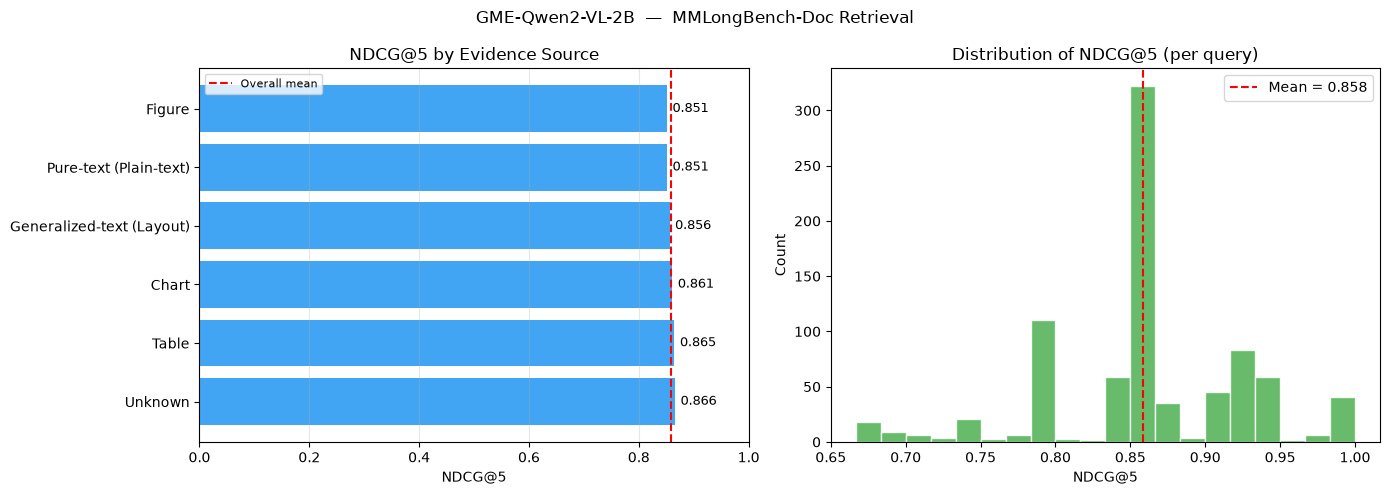

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# NDCG@5 by evidence source
ax = axes[0]
srcs = by_src.index.tolist()
vals = by_src[f'NDCG@{TOP_K}'].tolist()
bars = ax.barh(srcs, vals, color='#2196F3', alpha=0.85)
for bar, v in zip(bars, vals):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontsize=9)
ax.axvline(df[ndcg_col].mean(), color='red', linestyle='--', linewidth=1.5, label='Overall mean')
ax.set_xlabel(f'NDCG@{TOP_K}')
ax.set_title(f'NDCG@{TOP_K} by Evidence Source')
ax.legend(fontsize=8)
ax.set_xlim(0, 1)
ax.grid(axis='x', alpha=0.3)

# Distribution of NDCG@5 scores
ax = axes[1]
ax.hist(df[ndcg_col], bins=20, color='#4CAF50', alpha=0.85, edgecolor='white')
ax.axvline(df[ndcg_col].mean(), color='red', linestyle='--',
           label=f'Mean = {df[ndcg_col].mean():.3f}')
ax.set_xlabel(f'NDCG@{TOP_K}')
ax.set_ylabel('Count')
ax.set_title(f'Distribution of NDCG@{TOP_K} (per query)')
ax.legend()

plt.suptitle('GME-Qwen2-VL-2B  —  MMLongBench-Doc Retrieval', fontsize=12)
plt.tight_layout()
plt.show()

In [13]:
# ── Failure analysis: hardest queries ────────────────────────────────────────
print(f'Bottom 10 queries (lowest NDCG@{TOP_K}) — where retrieval fails:')
worst = df.nsmallest(10, ndcg_col)[['query_id','doc_type','evidence_src','n_pages',ndcg_col,'mrr']]
display(worst)

# Show the actual questions for the worst cases
print()
print('Questions text:')
for _, row in worst.iterrows():
    q = queries[row['query_id']]
    m = qa_meta.get(row['query_id'], {})
    print(f'  [{row["query_id"]}] {q["query"][:80]}...')
    print(f'         doc_type={m.get("doc_type","?")}  answer={m.get("answer","?")[:40]}')
    print()

Bottom 10 queries (lowest NDCG@5) — where retrieval fails:


,query_id,doc_type,evidence_src,n_pages,ndcg@5,mrr
24,26,Research report / Introduction,Figure,20,0.666667,1.0
94,113,Guidebook,Figure,40,0.666667,1.0
117,142,Research report / Introduction,Unknown,20,0.666667,1.0
143,177,Research report / Introduction,Pure-text (Plain-text),45,0.666667,1.0
204,264,Guidebook,Figure,38,0.666667,1.0
235,309,Administration/Industry file,Figure,40,0.666667,1.0
460,619,Academic paper,Chart,77,0.666667,1.0
483,650,Brochure,Pure-text (Plain-text),23,0.666667,1.0
606,812,Research report / Introduction,Unknown,61,0.666667,1.0
609,816,Research report / Introduction,Figure,30,0.666667,1.0



Questions text:
  [26] What is the web address in the orange box in page 47 that gives the Wiki Query S...
         doc_type=Research report / Introduction  answer=10

  [113] Which individual lead this program?...
         doc_type=Research report / Introduction  answer=6

  [142] What is the 8th (out of top10) findings listed in this presentation?...
         doc_type=Research report / Introduction  answer=6

  [177] What is the gap of 65+ people with College graduate contain a cell phone and a t...
         doc_type=Research report / Introduction  answer=4

  [264] Compared to Trump in January 2019, what higher percentage of Republicans believe...
         doc_type=Research report / Introduction  answer=24

  [309] What multiple of the 2014 e-commerce sales was achieved in 2018?...
         doc_type=Guidebook  answer=3.6.8  Flat surface for better maintenan

  [619] Among the most important applications listed, which one is shown a picture of th...
         doc_type=Tutorial/Worksh

## 7. Export Results

In [14]:
df.to_csv(CACHE_DIR / 'mmlongbench_retrieval_results.csv', index=False)
by_src.to_csv(CACHE_DIR / 'mmlongbench_by_source.csv')
by_type.to_csv(CACHE_DIR / 'mmlongbench_by_doctype.csv')

summary = {
    'model': EMBEDDING_MODEL,
    'benchmark': 'MMLongBench-Doc',
    'n_queries': len(df),
    f'ndcg@{TOP_K}': round(float(df[ndcg_col].mean()), 4),
    f'hit@{TOP_K}':  round(float(df[hit_col].mean()), 4),
    'mrr':           round(float(df['mrr'].mean()), 4),
}
(CACHE_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))

print('Results saved to', CACHE_DIR)
print(json.dumps(summary, indent=2))

Results saved to /data1/ldejesus/repos/public/colette/app_mmlongbench_eval
{
  "model": "Alibaba-NLP/gme-Qwen2-VL-2B-Instruct",
  "benchmark": "MMLongBench-Doc",
  "n_queries": 838,
  "ndcg@5": 0.8583,
  "hit@5": 1.0,
  "mrr": 1.0
}


## 8. Next Steps — Phase 2: Full Pipeline

To evaluate all 7 colette retrieval methods (embedding, text_search, hybrid, hindex, embed+hindex, text+hindex, hybrid+hindex) on MMLongBench-Doc, we need the actual PDF files.

**Option A — Official download:**  
The MMLongBench-Doc GitHub (`mayubo2333/MMLongBench-Doc`) has a download script for the 135 PDFs from their public sources.

**Option B — Reconstruct from high-res images:**  
Use `AHS-uni/mmlongbenchdoc-corpus` (2550×3300 JPEG pages) and reconstruct PDFs with `img2pdf`.

**Pipeline steps (once PDFs are available):**
1. Copy PDFs into a colette app directory
2. Run `setup_eval_service.ipynb`-style indexing (OCR, embedding, hindex building)
3. Run the 7-method evaluation loop (same as `evaluate_retrieval.ipynb`)
4. Report results against published GPT-4o baseline (44.9% F1 on VQA)
